# 2.4_scan_duration 扫描时长差异 — sub-01 ses-retest

N×TR 为名义时长，最后与第一采样点跨度是 (N−1)×TR；censor 后另有有效时长。

同时记录名义时长、采样跨度、有效观测时间和连续段；最短有效时长需由下游目标预先规定。

真实输入、处理前后、可复用关键代码、可视化与量化均在下面。两次采集仅教学few-shot，不能确定最优方法。

**限制：** 不规定普适最短秒数；下游可靠性未测。

In [1]:
from pathlib import Path
import sys, os, importlib.util, json, inspect
ROOT = Path(os.environ["FMRI_REFERENCE_ROOT"]).resolve() if "FMRI_REFERENCE_ROOT" in os.environ else next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/"fmri_reference"/"core.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from repository or set FMRI_REFERENCE_ROOT")
sys.path.insert(0, str(ROOT))
from fmri_reference.core import load_sample
spec = importlib.util.spec_from_file_location("category_reference", ROOT / "02_temporal_inconsistency/2.4_scan_duration/src/reference.py")
reference = importlib.util.module_from_spec(spec); spec.loader.exec_module(reference)
SESSION = "retest"
sample = load_sample(ROOT, SESSION)
print("REAL INPUT:", sample["path"])
print(json.dumps(sample["geometry"], indent=2))
print({k:v for k,v in sample["timing"].items() if k != "onsets_seconds"})
print("before mean/std:", sample["signals"].mean(), sample["signals"].std(ddof=1))


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


REAL INPUT: /Users/liuxiang/fMRI-preprocess/standard-reference/data/ds000114/sub-01/ses-retest/func/sub-01_ses-retest_task-fingerfootlips_bold.nii.gz
{
  "shape": [
    64,
    64,
    30,
    184
  ],
  "orientation": [
    "L",
    "A",
    "S"
  ],
  "spacing_mm": [
    3.999999997183861,
    3.999999857818425,
    3.9999644753281265
  ],
  "qform_code": 1,
  "sform_code": 1,
  "qform_sform_disagree": false,
  "affine_ras_mm": [
    [
      -3.9941670894622803,
      -0.21387556195259094,
      -0.030091872438788414,
      131.2411651611328
    ],
    [
      -0.2149735540151596,
      3.9901509284973145,
      0.18016961216926575,
      -102.3945083618164
    ],
    [
      -0.02038651518523693,
      -0.18152596056461334,
      3.995791435241699,
      -46.10886001586914
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ]
}
{'tr_seconds': 2.5, 'sampling_hz': 0.4, 'nyquist_hz': 0.2, 'n_volumes': 184, 'sample_span_seconds': 457.5, 'nominal_duration_seconds': 460.0}
bef

## 关键函数与执行

所有源码可追踪。配准/生理/组织输入不存在时，不生成虚构校正结果。

In [2]:
print(inspect.getsource(reference.apply))

def timing(img,metadata):
    if len(img.shape)!=4:raise ValueError('BOLD must be 4D')
    if 'VolumeTiming' in metadata:raise ValueError('Variable TR needs an explicit irregular-time workflow')
    tr=float(metadata['RepetitionTime'])
    if not np.isfinite(tr) or tr<=0:raise ValueError('TR must be positive seconds')
    unit=img.header.get_xyzt_units()[1]
    factor={'sec':1,'msec':1e-3,'usec':1e-6}.get(unit)
    if factor is None:raise ValueError('Unknown NIfTI time unit')
    if not np.isclose(img.header.get_zooms()[3]*factor,tr,rtol=1e-4):raise ValueError('JSON/header TR conflict')
    n=img.shape[3]
    return {'tr_seconds':tr,'sampling_hz':1/tr,'nyquist_hz':.5/tr,'n_volumes':n,
            'sample_span_seconds':(n-1)*tr,'nominal_duration_seconds':n*tr,
            'onsets_seconds':(np.arange(n)*tr).tolist()}



{
  "input": "data/ds000114/sub-01/ses-retest/func/sub-01_ses-retest_task-fingerfootlips_bold.nii.gz",
  "session": "retest",
  "kind": "duration",
  "tr_seconds": 2.5,
  "n_input": 184,
  "feature_scope": "128 deterministic voxels from estimated EPI mask, not full brain",
  "before": {
    "shape": [
      184,
      128
    ],
    "mean_abs": 1188.474312160326,
    "median_sample_std": 37.16732411570946,
    "q01": 179.0,
    "q99": 1848.0
  },
  "production_pipeline": "NOT_RUN",
  "scientific_best_method": "INSUFFICIENT_EVIDENCE",
  "clock": {
    "tr_seconds": 2.5,
    "sampling_hz": 0.4,
    "nyquist_hz": 0.2,
    "n_volumes": 184,
    "sample_span_seconds": 457.5,
    "nominal_duration_seconds": 460.0,
    "onsets_seconds": [
      0.0,
      2.5,
      5.0,
      7.5,
      10.0,
      12.5,
      15.0,
      17.5,
      20.0,
      22.5,
      25.0,
      27.5,
      30.0,
      32.5,
      35.0,
      37.5,
      40.0,
      42.5,
      45.0,
      47.5,
      50.0,
      52.5

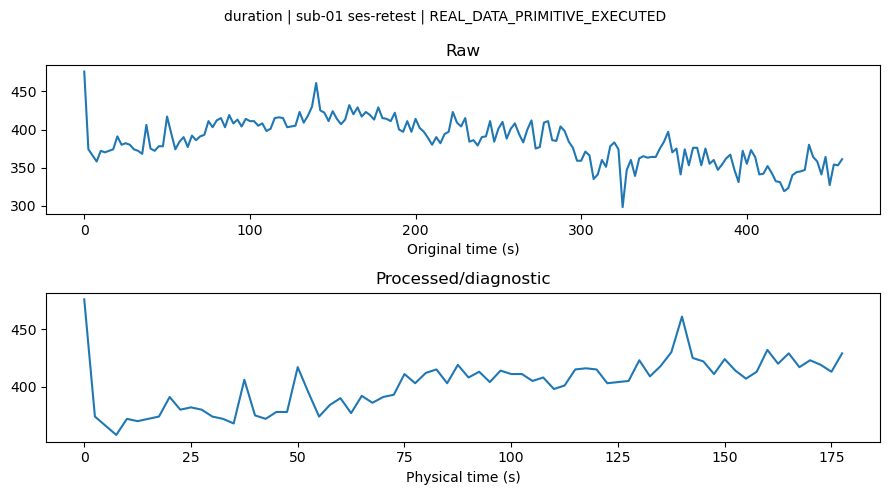

In [3]:
metrics, fig = reference.demonstrate(ROOT, SESSION, variant=1, outdir=ROOT/"02_temporal_inconsistency/2.4_scan_duration/results/retest")
print(json.dumps(metrics, indent=2))
from IPython.display import display
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

## 常见错误与阻止机制

以下故意提供不满足科学前提的输入。报错是负对照，不是处理失败被掩盖。

In [4]:
try:
    reference.error_example("duration")
except (ValueError, FileNotFoundError) as e:
    print("EXPECTED REJECTION:", type(e).__name__, str(e))
else:
    raise AssertionError("Invalid scientific input was accepted")

EXPECTED REJECTION: ValueError TR must be positive


## 解释与后续验证

数值不变性/投影正交性只验证实现数学性质。更低DVARS、更高tSNR、更低配准目标值不是神经信号保真证明。正式推荐需同数据、固定参数、跨受试者的独立下游证据。详见本小类README、references和根目录验证报告。